<h1><center> Linear Regression Theory and Code

<h3> 1)- Code avec Scikit-Learn

Ici le modéle utilise la méthode analytique directe pour calculer les valeurs de w et b !

In [103]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [104]:
data = pd.DataFrame({
                        'Heures_etude': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                        'Note': [42, 47, 49, 53, 61, 64, 69, 72, 75, 79]
                        
                        #'Note': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100] # bon modéle linéaire 
                        
                        #'Note' : [1, 4, 9, 16, 25, 36, 47, 64, 81, 100 ]  # un mauvais modéle 
                        
                        
                        
                        #'Heures_etude': [1, 2, 3], # cas pratique
                        #'Note': [42, 47, 49]
})

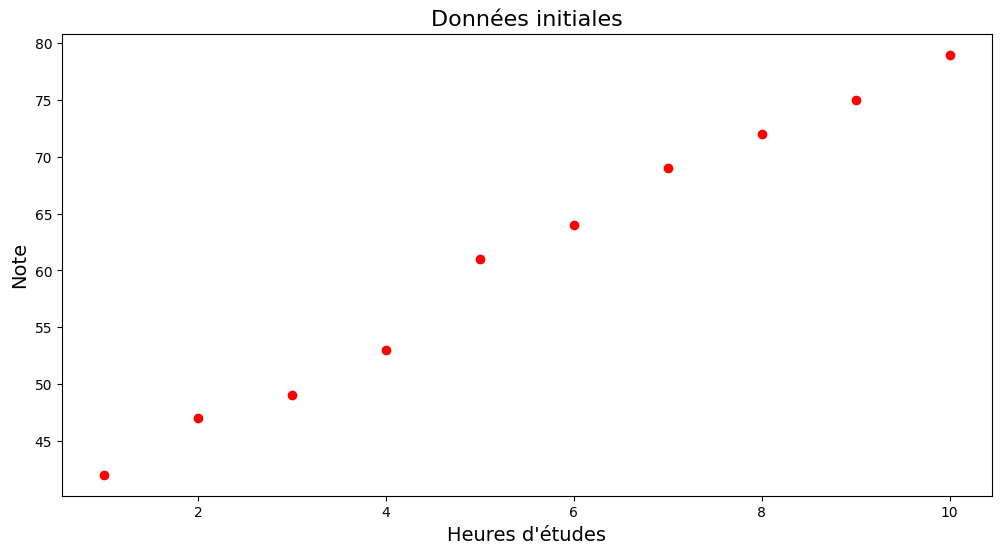

In [105]:
plt.figure(figsize= (12,6))
plt.scatter(x= data['Heures_etude'], y= data['Note'], color= 'red')
plt.title("Données initiales", fontsize= 16)
plt.xlabel('Heures d\'études', fontsize= 14)
plt.ylabel('Note', fontsize= 14)
plt.show()

In [106]:
X= data[['Heures_etude']]
y= data[['Note']]

In [107]:
# Avant de faire fit(X,y) voici ce qui se passe derriére:
# 1)- On calcule la moyenne

print("La moyenne de X est : ", int(X.mean()))
print("La moyenne de y est : ", int(y.mean()))

La moyenne de X est :  5
La moyenne de y est :  61


In [108]:
# 2)- On calcule la valeur exacte de w et b en utilisant 

# w= [ ∑ (xi − xˉ)(yi - yˉ) ] / [ ∑ (xi − xˉ)^2 ]

# b= yˉ ​−w⋅ xˉ




In [109]:
model = LinearRegression()
model.fit(X, y)


LinearRegression()

In [110]:
y_pred = model.predict(X)
y_pred

array([[42.14545455],
       [46.35757576],
       [50.56969697],
       [54.78181818],
       [58.99393939],
       [63.20606061],
       [67.41818182],
       [71.63030303],
       [75.84242424],
       [80.05454545]])

In [111]:
print('la pente est :  ', model.coef_[0])
print('l\'ordonnée à l\'origine est : ', model.intercept_)

la pente est :   [4.21212121]
l'ordonnée à l'origine est :  [37.93333333]


In [112]:
print('La droite est : ', model.coef_[0],'X +', model.intercept_)

La droite est :  [4.21212121] X + [37.93333333]


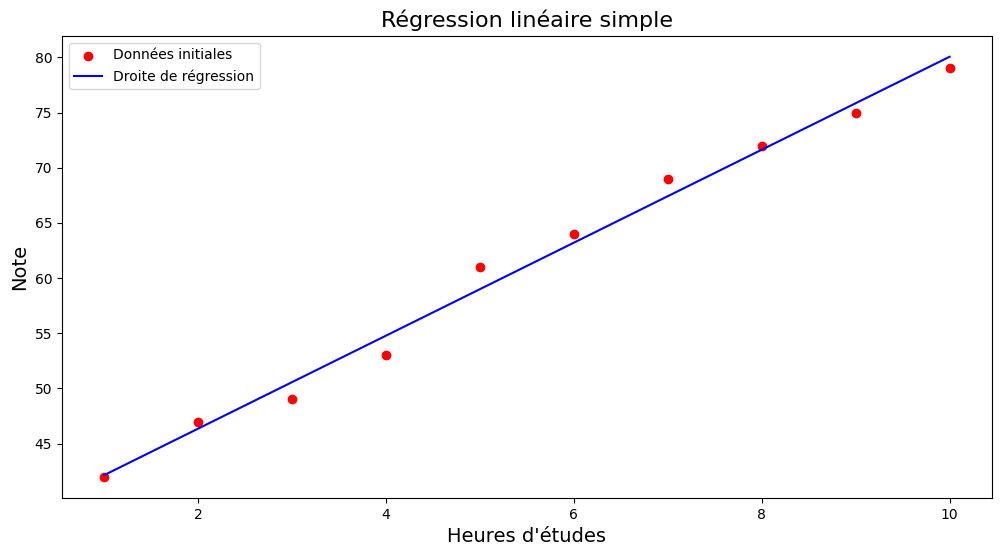

In [113]:
plt.figure(figsize= (12,6))
plt.scatter(x= data['Heures_etude'], y= data['Note'], color= 'red', label= 'Données initiales')
plt.plot(X, y_pred, color= 'blue', label='Droite de régression')
plt.title("Régression linéaire simple", fontsize= 16)
plt.xlabel('Heures d\'études', fontsize= 14)
plt.ylabel('Note', fontsize= 14)
plt.legend()
plt.show()

In [114]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y, y_pred)
print(mse)

1.518787878787879


<p> Donc ici on n'a pas d'utilisation de l'algorithme de gradient descente, on utilise une méthode directe.

<h3> 2)- Implémentation de la régression liniaire from scratch :)

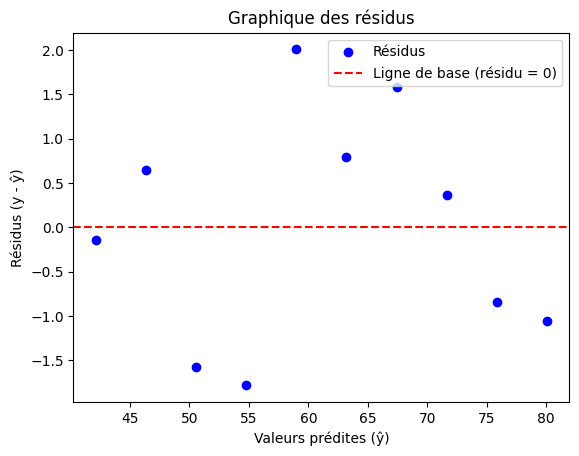

In [115]:
residuals = y - y_pred

plt.scatter(y_pred, residuals, color='blue', label="Résidus")
plt.axhline(y=0, color='red', linestyle='--', label="Ligne de base (résidu = 0)")
plt.title("Graphique des résidus")
plt.xlabel("Valeurs prédites (ŷ)")
plt.ylabel("Résidus (y - ŷ)")
plt.legend()
plt.show()

In [116]:
residuals

,Note
0,-0.145455
1,0.642424
2,-1.569697
3,-1.781818
4,2.006061
5,0.793939
6,1.581818
7,0.369697
8,-0.842424
9,-1.054545


In [118]:
from sklearn.metrics import r2_score

rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)


print("R2 score = ", r2)
print("RMSE = ", rmse)


R2 score =  0.9897302868430058
RMSE =  1.2323911224882622
